# Intersection Safety Assessment Reporting with a Lightweight LLM

In [2]:
# ============================================================
# # Intersection Safety Assessment Reporting with a Lightweight LLM
# # Google Colab end-to-end notebook
# #
# # What this notebook does:
# # 1. Installs dependencies
# # 2. Generates a 300-sample synthetic instruction dataset
# # 3. Saves train / validation / test splits
# # 4. Fine-tunes a lightweight LLM with LoRA
# # 5. Prefers Unsloth; falls back to Transformers + PEFT if needed
# # 6. Evaluates base vs fine-tuned model on the test set
# # 7. Saves outputs, comparisons, and an evaluation sheet
# ============================================================


# ============================================================
# # 1) Install dependencies
# # - This section tries to install Unsloth first.
# # - If Unsloth import fails later, the notebook will fall back
# #   to standard Hugging Face Transformers + PEFT.
# ============================================================

!pip -q install -U pip setuptools wheel
!pip -q install -U transformers datasets accelerate peft trl bitsandbytes sentencepiece scikit-learn pandas openpyxl

# Optional Unsloth install attempt
!pip -q install unsloth || echo "Unsloth install from PyPI failed; will try fallback path later."


# ============================================================
# # 2) Imports and configuration
# # - Set random seeds and output paths.
# # - Choose a small instruct model suitable for Colab.
# ============================================================

import os
import json
import math
import random
import shutil
import warnings
from dataclasses import dataclass
from typing import Dict, List

import pandas as pd
import numpy as np
import torch
from datasets import load_dataset, DatasetDict

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUTPUT_DIR = "/content/intersection_safety_project"
DATA_DIR = os.path.join(OUTPUT_DIR, "data")
MODEL_DIR = os.path.join(OUTPUT_DIR, "model_output")
EVAL_DIR = os.path.join(OUTPUT_DIR, "evaluation")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(EVAL_DIR, exist_ok=True)

# Lightweight model choice
# Prefer a small instruct model to keep memory and training time low.
BASE_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

SYSTEM_PROMPT = (
    "You are an intersection safety reporting assistant. "
    "Use only the provided structured safety indicators. "
    "Do not invent missing facts. "
    "Write a concise and professional Intersection Safety Assessment Report with these sections: "
    "Safety Status Summary, Main Risk Factors, Interpretation, Recommended Countermeasures, and Conclusion."
)

INSTRUCTION = (
    "Generate a concise Intersection Safety Assessment Report using only the provided structured safety indicators."
)

MAX_SEQ_LENGTH = 1024
NUM_SAMPLES = 300
RISK_DISTRIBUTION = {"low": 90, "medium": 100, "high": 75, "critical": 35}


# ============================================================
# # 3) Justification for using an LLM
# # - This task is report generation, not raw crash prediction.
# # - LLMs are useful because they convert structured safety indicators
# #   into consistent, sectioned, technical reports.
# ============================================================

justification_text = """
Why an LLM is appropriate:
This task is structured technical report generation rather than raw safety prediction.
The model receives already-defined intersection safety indicators and converts them into
clear, concise, and professional assessment reports. This matches LLM strengths in
controlled summarization, sectioned writing, domain-specific phrasing, and consistency.
"""

print(justification_text)


# ============================================================
# # 4) Define synthetic data schema and generation rules
# # - We generate realistic transportation safety cases.
# # - Risk levels influence crash counts, speed, conflicts, and conditions.
# ============================================================

controls = ["signalized", "stop-controlled", "roundabout", "uncontrolled"]
areas = ["urban", "suburban", "rural"]
lighting = ["good", "moderate", "poor"]
surface = ["good", "fair", "poor"]
weather = ["dry", "rainy", "mixed", "fog-prone"]
ped = ["low", "medium", "high"]
bike = ["low", "medium", "high"]
turn_complexity = ["low", "medium", "high"]
school_zone = ["yes", "no"]
land_use = ["residential", "commercial", "school zone", "industrial", "mixed use"]

@dataclass
class IntersectionCase:
    intersection_id: str
    control_type: str
    area_type: str
    annual_total_crashes: int
    fatal_crashes: int
    serious_injury_crashes: int
    minor_crashes: int
    average_approach_speed_kph: int
    posted_speed_limit_kph: int
    intersection_aadt: int
    peak_hour_turning_volume: int
    number_of_approaches: int
    through_lane_count: int
    pedestrian_activity: str
    bicycle_activity: str
    lighting_condition: str
    surface_condition: str
    weather_pattern: str
    turning_movement_complexity: str
    sight_distance_adequacy_score: int
    school_zone_presence: str
    nearby_land_use: str
    observed_delay_seconds: int
    conflict_point_index: int
    risk_level: str

def weighted_choice(items, weights):
    return random.choices(items, weights=weights, k=1)[0]

def build_case(idx: int, risk: str) -> Dict:
    control = weighted_choice(controls, [0.35, 0.25, 0.15, 0.25])
    area = weighted_choice(areas, [0.50, 0.30, 0.20])
    speed_limit = random.choice([30, 40, 50, 60, 70])

    if risk == "low":
        total = random.randint(0, 5)
        fatal = 0
        serious = random.randint(0, 1)
        avg_speed = random.randint(max(20, speed_limit - 10), speed_limit + 5)
        aadt = random.randint(3000, 22000)
        turn_vol = random.randint(80, 350)
        conflict = random.randint(5, 20)
        delay = random.randint(8, 25)
        lanes = random.randint(1, 3)
        light = weighted_choice(lighting, [0.70, 0.25, 0.05])
        surf = weighted_choice(surface, [0.65, 0.30, 0.05])
        ped_level = weighted_choice(ped, [0.60, 0.30, 0.10])
        bike_level = weighted_choice(bike, [0.65, 0.25, 0.10])
        turn_comp = weighted_choice(turn_complexity, [0.60, 0.30, 0.10])
        sight = random.randint(4, 9)

    elif risk == "medium":
        total = random.randint(4, 10)
        fatal = random.randint(0, 1)
        serious = random.randint(1, 3)
        avg_speed = random.randint(max(25, speed_limit - 5), speed_limit + 10)
        aadt = random.randint(8000, 35000)
        turn_vol = random.randint(180, 650)
        conflict = random.randint(15, 35)
        delay = random.randint(18, 45)
        lanes = random.randint(2, 4)
        light = weighted_choice(lighting, [0.30, 0.50, 0.20])
        surf = weighted_choice(surface, [0.30, 0.50, 0.20])
        ped_level = weighted_choice(ped, [0.30, 0.45, 0.25])
        bike_level = weighted_choice(bike, [0.40, 0.40, 0.20])
        turn_comp = weighted_choice(turn_complexity, [0.25, 0.50, 0.25])
        sight = random.randint(3, 7)

    elif risk == "high":
        total = random.randint(9, 18)
        fatal = random.randint(1, 2)
        serious = random.randint(3, 5)
        avg_speed = random.randint(speed_limit + 3, speed_limit + 18)
        aadt = random.randint(15000, 55000)
        turn_vol = random.randint(400, 1000)
        conflict = random.randint(28, 55)
        delay = random.randint(30, 70)
        lanes = random.randint(2, 5)
        light = weighted_choice(lighting, [0.10, 0.35, 0.55])
        surf = weighted_choice(surface, [0.10, 0.45, 0.45])
        ped_level = weighted_choice(ped, [0.15, 0.35, 0.50])
        bike_level = weighted_choice(bike, [0.20, 0.35, 0.45])
        turn_comp = weighted_choice(turn_complexity, [0.15, 0.35, 0.50])
        sight = random.randint(2, 5)

    else:
        total = random.randint(16, 30)
        fatal = random.randint(2, 4)
        serious = random.randint(5, 8)
        avg_speed = random.randint(speed_limit + 8, speed_limit + 22)
        aadt = random.randint(25000, 80000)
        turn_vol = random.randint(700, 1500)
        conflict = random.randint(45, 80)
        delay = random.randint(45, 100)
        lanes = random.randint(3, 6)
        light = weighted_choice(lighting, [0.05, 0.20, 0.75])
        surf = weighted_choice(surface, [0.05, 0.25, 0.70])
        ped_level = weighted_choice(ped, [0.10, 0.20, 0.70])
        bike_level = weighted_choice(bike, [0.15, 0.25, 0.60])
        turn_comp = weighted_choice(turn_complexity, [0.10, 0.25, 0.65])
        sight = random.randint(1, 4)

    minor = max(total - fatal - serious, 0)

    if control == "roundabout":
        delay = max(5, delay - 10)
        conflict = max(3, conflict - 5)

    if control == "uncontrolled" and risk in ("high", "critical"):
        conflict += 5

    school = weighted_choice(school_zone, [0.20, 0.80]) if area != "rural" else weighted_choice(school_zone, [0.08, 0.92])

    case = IntersectionCase(
        intersection_id=f"INT-{idx:03d}",
        control_type=control,
        area_type=area,
        annual_total_crashes=total,
        fatal_crashes=fatal,
        serious_injury_crashes=serious,
        minor_crashes=minor,
        average_approach_speed_kph=avg_speed,
        posted_speed_limit_kph=speed_limit,
        intersection_aadt=aadt,
        peak_hour_turning_volume=turn_vol,
        number_of_approaches=random.randint(3, 5),
        through_lane_count=lanes,
        pedestrian_activity=ped_level,
        bicycle_activity=bike_level,
        lighting_condition=light,
        surface_condition=surf,
        weather_pattern=weighted_choice(weather, [0.45, 0.20, 0.25, 0.10]),
        turning_movement_complexity=turn_comp,
        sight_distance_adequacy_score=sight,
        school_zone_presence=school,
        nearby_land_use=weighted_choice(land_use, [0.20, 0.30, 0.15, 0.10, 0.25]),
        observed_delay_seconds=delay,
        conflict_point_index=conflict,
        risk_level=risk,
    )
    return case.__dict__


# ============================================================
# # 5) Define report-writing logic
# # - This creates the target output for each synthetic sample.
# # - The model will learn to reproduce this structure and style.
# ============================================================

def summarize_factors(case: Dict) -> List[str]:
    factors = []

    if case["fatal_crashes"] >= 2:
        factors.append("multiple fatal crashes")
    elif case["fatal_crashes"] == 1:
        factors.append("a fatal crash history")

    if case["serious_injury_crashes"] >= 5:
        factors.append("a high number of serious injury crashes")
    elif case["serious_injury_crashes"] >= 2:
        factors.append("serious injury crash occurrence")

    speed_over = case["average_approach_speed_kph"] - case["posted_speed_limit_kph"]
    if speed_over >= 10:
        factors.append("approach speed well above the posted limit")
    elif speed_over >= 3:
        factors.append("approach speed above the posted limit")

    if case["lighting_condition"] == "poor":
        factors.append("poor lighting")

    if case["surface_condition"] == "poor":
        factors.append("poor pavement condition")

    if case["pedestrian_activity"] == "high":
        factors.append("high pedestrian activity")

    if case["bicycle_activity"] == "high":
        factors.append("high bicycle activity")

    if case["turning_movement_complexity"] == "high":
        factors.append("complex turning movements")

    if case["sight_distance_adequacy_score"] <= 3:
        factors.append("restricted sight distance")

    if case["observed_delay_seconds"] >= 50:
        factors.append("substantial operational delay")

    if case["conflict_point_index"] >= 45:
        factors.append("elevated conflict exposure")

    if case["school_zone_presence"] == "yes":
        factors.append("school-zone exposure")

    if not factors:
        factors.append("the observed crash history and operating conditions")

    # deduplicate while preserving order
    seen = set()
    result = []
    for f in factors:
        if f not in seen:
            result.append(f)
            seen.add(f)
    return result[:5]

def attention_phrase(risk: str) -> str:
    return {
        "low": "routine monitoring",
        "medium": "targeted safety improvement",
        "high": "priority intervention",
        "critical": "urgent corrective action",
    }[risk]

def generate_report(case: Dict) -> str:
    factors = summarize_factors(case)
    if len(factors) == 1:
        factor_text = factors[0]
    else:
        factor_text = ", ".join(factors[:-1]) + ", and " + factors[-1]

    summary = (
        f"Safety Status Summary: Intersection {case['intersection_id']} shows a {case['risk_level']} safety condition. "
        f"The assessment reflects the observed crash history, injury severity, approach speeds, operational conditions, "
        f"and vulnerable-road-user exposure. Key concerns include {factor_text}. "
        f"Overall, this location requires {attention_phrase(case['risk_level'])}."
    )

    main_risks = (
        f"Main Risk Factors: The principal risk factors are {factor_text}. "
        f"Supporting indicators include control type {case['control_type']}, traffic exposure of approximately "
        f"{case['intersection_aadt']} AADT, peak-hour turning volume of {case['peak_hour_turning_volume']}, "
        f"lighting rated {case['lighting_condition']}, and surface condition rated {case['surface_condition']}."
    )

    if case["risk_level"] == "low":
        interpretation = (
            "Interpretation: The intersection currently operates with relatively stable safety performance. "
            "The available indicators do not suggest a severe breakdown in safety, but continued monitoring is appropriate."
        )
    elif case["risk_level"] == "medium":
        interpretation = (
            "Interpretation: The intersection presents a moderate safety concern. "
            "Its crash and operating profile indicates the need for preventive treatment before risk escalates."
        )
    elif case["risk_level"] == "high":
        interpretation = (
            "Interpretation: The intersection is exposed to elevated safety risk due to the combined effect of crash severity, "
            "approach speed, turning complexity, and user conflict. Targeted intervention is justified."
        )
    else:
        interpretation = (
            "Interpretation: The intersection reflects a critical safety condition with multiple indicators associated with severe crash outcomes. "
            "Immediate corrective action is warranted."
        )

    actions = []
    if case["average_approach_speed_kph"] > case["posted_speed_limit_kph"] + 2:
        actions.append("speed management and enforcement review")
    if case["lighting_condition"] in ("moderate", "poor"):
        actions.append("lighting and visibility improvement")
    if case["surface_condition"] in ("fair", "poor"):
        actions.append("surface maintenance or rehabilitation")
    if case["pedestrian_activity"] in ("medium", "high"):
        actions.append("pedestrian crossing and protection enhancement")
    if case["bicycle_activity"] == "high":
        actions.append("bicycle accommodation review")
    if case["turning_movement_complexity"] == "high":
        actions.append("turning-movement channelization or signal phasing review")
    if case["sight_distance_adequacy_score"] <= 3:
        actions.append("sight-distance improvement")
    if case["control_type"] in ("stop-controlled", "uncontrolled") and case["risk_level"] in ("high", "critical"):
        actions.append("intersection control reassessment")
    if case["school_zone_presence"] == "yes":
        actions.append("school-zone safety treatment")

    # dedupe
    deduped_actions = []
    for a in actions:
        if a not in deduped_actions:
            deduped_actions.append(a)

    if not deduped_actions:
        deduped_actions = ["continued monitoring and low-cost safety treatment"]

    if len(deduped_actions) == 1:
        action_text = deduped_actions[0]
    else:
        action_text = ", ".join(deduped_actions[:-1]) + ", and " + deduped_actions[-1]

    recommendations = f"Recommended Countermeasures: Priority actions include {action_text}."

    conclusion = (
        f"Conclusion: Intersection {case['intersection_id']} should be treated as a {case['risk_level']} priority location. "
        f"Planned actions should align with the observed crash pattern, traffic exposure, and operational context."
    )

    return " ".join([summary, main_risks, interpretation, recommendations, conclusion])

def case_to_user_text(case: Dict) -> str:
    lines = ["Generate a concise Intersection Safety Assessment Report for the following case:"]
    for k, v in case.items():
        lines.append(f"{k}: {v}")
    return "\n".join(lines)


# ============================================================
# # 6) Generate the 300-sample synthetic instruction dataset
# # - Each record contains:
# #   instruction
# #   structured input
# #   output report
# #   chat-style messages for training
# ============================================================

records = []
idx = 1

for risk, count in RISK_DISTRIBUTION.items():
    for _ in range(count):
        case = build_case(idx, risk)
        report = generate_report(case)

        records.append({
            "instruction": INSTRUCTION,
            "input": case,
            "output": report,
            "messages": [
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": case_to_user_text(case)},
                {"role": "assistant", "content": report},
            ],
        })
        idx += 1

random.shuffle(records)

print(f"Generated {len(records)} samples.")
print("Sample output:\n")
print(records[0]["output"][:900])


# ============================================================
# # 7) Save full dataset and train / validation / test splits
# # - 70% train, 15% validation, 15% test
# ============================================================

train_records = records[:210]
valid_records = records[210:255]
test_records = records[255:]

def save_jsonl(path: str, items: List[Dict]):
    with open(path, "w", encoding="utf-8") as f:
        for item in items:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")

train_path = os.path.join(DATA_DIR, "train.jsonl")
valid_path = os.path.join(DATA_DIR, "valid.jsonl")
test_path  = os.path.join(DATA_DIR, "test.jsonl")
all_path   = os.path.join(DATA_DIR, "all_300_instruction_dataset.jsonl")

save_jsonl(train_path, train_records)
save_jsonl(valid_path, valid_records)
save_jsonl(test_path, test_records)
save_jsonl(all_path, records)

# Save review-friendly tabular files
flat_rows = []
for r in records:
    row = dict(r["input"])
    row["instruction"] = r["instruction"]
    row["output_report"] = r["output"]
    flat_rows.append(row)

flat_df = pd.DataFrame(flat_rows)
excel_path = os.path.join(DATA_DIR, "intersection_safety_dataset_300.xlsx")
csv_path = os.path.join(DATA_DIR, "intersection_safety_dataset_300.csv")
flat_df.to_excel(excel_path, index=False)
flat_df.to_csv(csv_path, index=False)

print("Saved dataset files:")
print(train_path)
print(valid_path)
print(test_path)
print(excel_path)


print("\n" * 2)
print("=" * 100)
print("# 7.1) Data Overview (from generated synthetic data)")
print("=" * 100)
display(flat_df.head())


# ============================================================
# # 8) Load dataset for training
# # - We use the chat-format "messages" field.
# ============================================================

dataset = load_dataset(
    "json",
    data_files={
        "train": train_path,
        "validation": valid_path,
        "test": test_path,
    },
)
print(dataset)


# ============================================================
# # 9) Try Unsloth first; fall back if unavailable
# # - Unsloth can reduce memory usage and speed up fine-tuning.
# # - If import fails, use standard Transformers + PEFT.
# ============================================================

USE_UNSLOTH = True
try:
    from unsloth import FastLanguageModel
    print("Using Unsloth.")
except Exception as e:
    USE_UNSLOTH = False
    print("Unsloth not available. Falling back to Transformers + PEFT.")
    print("Reason:", repr(e))

from transformers import AutoTokenizer, AutoModelForCausalLM, TrainingArguments, Trainer, DataCollatorForLanguageModeling
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from trl import SFTTrainer, SFTConfig


# ============================================================
# # 10) Load base model and tokenizer
# # - Unsloth path: FastLanguageModel
# # - Fallback path: Transformers + bitsandbytes 4-bit
# ============================================================

if USE_UNSLOTH:
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=BASE_MODEL_NAME,
        max_seq_length=MAX_SEQ_LENGTH,
        dtype=None,
        load_in_4bit=True,
    )

    model = FastLanguageModel.get_peft_model(
        model,
        r=16,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
        lora_alpha=16,
        lora_dropout=0.0,
        bias="none",
        use_gradient_checkpointing="unsloth",
        random_state=SEED,
    )
else:
    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME, trust_remote_code=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_NAME,
        trust_remote_code=True,
        device_map="auto",
        load_in_4bit=True,
    )

    model = prepare_model_for_kbit_training(model)

    peft_config = LoraConfig(
        r=16,
        lora_alpha=16,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
        lora_dropout=0.0,
        bias="none",
        task_type="CAUSAL_LM",
    )
    model = get_peft_model(model, peft_config)


# ============================================================
# # 11) Format the dataset into training text
# # - For each record, we render the chat messages into a single string.
# # - This is the text the SFT trainer will learn from.
# ============================================================

def format_chat_batch(batch):
    texts = []
    for messages in batch["messages"]:
        if hasattr(tokenizer, "apply_chat_template"):
            text = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=False,
            )
        else:
            # Simple fallback if chat template is unavailable
            parts = []
            for m in messages:
                parts.append(f"{m['role'].upper()}: {m['content']}")
            text = "\n\n".join(parts)
        texts.append(text)
    return {"text": texts}

dataset = dataset.map(format_chat_batch, batched=True)

print("Preview formatted sample:\n")
print(dataset["train"][0]["text"][:2000])


# ============================================================
# # 12) Fine-tune the model
# # - Keep memory and compute low:
# #   small batch size
# #   gradient accumulation
# #   2 epochs
# #   4-bit loading
# #   LoRA adapters only
# ============================================================

if USE_UNSLOTH:
    trainer = SFTTrainer(
        model=model,
        tokenizer=tokenizer,
        train_dataset=dataset["train"],
        eval_dataset=dataset["validation"],
        args=SFTConfig(
            dataset_text_field="text",
            max_seq_length=MAX_SEQ_LENGTH,
            output_dir=MODEL_DIR,
            per_device_train_batch_size=2,
            per_device_eval_batch_size=2,
            gradient_accumulation_steps=4,
            learning_rate=2e-4,
            num_train_epochs=2,
            logging_steps=10,
            eval_strategy="steps",
            eval_steps=20,
            save_strategy="steps",
            save_steps=20,
            save_total_limit=2,
            optim="adamw_8bit",
            lr_scheduler_type="linear",
            weight_decay=0.01,
            report_to="none",
            packing=False,
            seed=SEED,
        ),
    )
else:
    # Tokenize text for fallback trainer
    def tokenize_fn(batch):
        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_SEQ_LENGTH,
            padding="max_length",
        )

    tokenized_dataset = dataset.map(tokenize_fn, batched=True, remove_columns=dataset["train"].column_names)

    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

    training_args = TrainingArguments(
        output_dir=MODEL_DIR,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=4,
        learning_rate=2e-4,
        num_train_epochs=2,
        logging_steps=10,
        eval_strategy="steps",
        eval_steps=20,
        save_strategy="steps",
        save_steps=20,
        save_total_limit=2,
        report_to="none",
        fp16=torch.cuda.is_available(),
        bf16=False,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_dataset["train"],
        eval_dataset=tokenized_dataset["validation"],
        data_collator=data_collator,
    )

print("Starting fine-tuning...")
train_result = trainer.train()
print(train_result)


# ============================================================
# # 13) Save the fine-tuned adapter / model
# ============================================================

trainer.model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)
print("Saved model output to:", MODEL_DIR)


# ============================================================
# # 14) Define inference helpers
# # - We compare the base model and fine-tuned model on the test set.
# ============================================================

def prepare_for_inference(model_obj):
    if USE_UNSLOTH:
        try:
            FastLanguageModel.for_inference(model_obj)
        except Exception:
            pass
    model_obj.eval()
    return model_obj

model = prepare_for_inference(model)

# Reload base model for comparison
if USE_UNSLOTH:
    base_model, base_tokenizer = FastLanguageModel.from_pretrained(
        model_name=BASE_MODEL_NAME,
        max_seq_length=MAX_SEQ_LENGTH,
        dtype=None,
        load_in_4bit=True,
    )
    base_model = prepare_for_inference(base_model)
else:
    base_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME, trust_remote_code=True)
    if base_tokenizer.pad_token is None:
        base_tokenizer.pad_token = base_tokenizer.eos_token
    base_model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_NAME,
        trust_remote_code=True,
        device_map="auto",
        load_in_4bit=True,
    )
    base_model = prepare_for_inference(base_model)

def generate_response(model_obj, tokenizer_obj, messages, max_new_tokens=260):
    if hasattr(tokenizer_obj, "apply_chat_template"):
        inputs = tokenizer_obj.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
        )
    else:
        prompt = "\n\n".join([f"{m['role'].upper()}: {m['content']}" for m in messages])
        inputs = tokenizer_obj(prompt, return_tensors="pt").input_ids

    inputs = inputs.to(model_obj.device if hasattr(model_obj, "device") else "cuda")

    with torch.no_grad():
        outputs = model_obj.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer_obj.eos_token_id,
        )

    text = tokenizer_obj.batch_decode(outputs, skip_special_tokens=True)[0]
    return text


# ============================================================
# # 15) Evaluation metrics
# # - Automatic structure score
# # - Simple factual overlap proxy
# # - Qualitative comparison output
# #
# # Note:
# # Full factuality and hallucination evaluation still benefits from
# # manual review, so we also save a review sheet.
# ============================================================

REQUIRED_SECTIONS = [
    "Safety Status Summary:",
    "Main Risk Factors:",
    "Interpretation:",
    "Recommended Countermeasures:",
    "Conclusion:"
]

def structure_score(text: str) -> int:
    return sum(section in text for section in REQUIRED_SECTIONS)

def factual_overlap_proxy(case: Dict, generated_text: str) -> float:
    # simple proxy: count how many visible key values appear in the output
    keys_to_check = [
        "intersection_id",
        "control_type",
        "risk_level",
        "intersection_aadt",
        "peak_hour_turning_volume",
        "lighting_condition",
        "surface_condition",
    ]
    hits = 0
    for k in keys_to_check:
        v = str(case[k])
        if v in generated_text:
            hits += 1
    return hits / len(keys_to_check)

comparison_rows = []
num_test = len(dataset["test"])

for i in range(num_test):
    sample_messages = dataset["test"][i]["messages"]
    case_input = test_records[i]["input"] if i < len(test_records) else None
    reference_output = sample_messages[2]["content"]

    base_output = generate_response(base_model, base_tokenizer, sample_messages[:2])
    finetuned_output = generate_response(model, tokenizer, sample_messages[:2])

    comparison_rows.append({
        "test_case_index": i,
        "intersection_id": case_input["intersection_id"],
        "risk_level": case_input["risk_level"],
        "reference_output": reference_output,
        "base_model_output": base_output,
        "fine_tuned_output": finetuned_output,
        "base_structure_score": structure_score(base_output),
        "fine_tuned_structure_score": structure_score(finetuned_output),
        "base_factual_overlap_proxy": factual_overlap_proxy(case_input, base_output),
        "fine_tuned_factual_overlap_proxy": factual_overlap_proxy(case_input, finetuned_output),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_csv = os.path.join(EVAL_DIR, "base_vs_finetuned_outputs.csv")
comparison_xlsx = os.path.join(EVAL_DIR, "base_vs_finetuned_outputs.xlsx")
comparison_df.to_csv(comparison_csv, index=False)
comparison_df.to_excel(comparison_xlsx, index=False)

print("Saved comparison files:")
print(comparison_csv)
print(comparison_xlsx)


print("\n" * 2)
print("=" * 100)
print("# 15.1) Quantitative Model Evaluation Summary")
print("=" * 100)

avg_base_structure_score = comparison_df['base_structure_score'].mean()
avg_finetuned_structure_score = comparison_df['fine_tuned_structure_score'].mean()
avg_base_factual_overlap_proxy = comparison_df['base_factual_overlap_proxy'].mean()
avg_finetuned_factual_overlap_proxy = comparison_df['fine_tuned_factual_overlap_proxy'].mean()

print(f"Average Base Model Structure Score: {avg_base_structure_score:.2f} / {len(REQUIRED_SECTIONS)}")
print(f"Average Fine-tuned Model Structure Score: {avg_finetuned_structure_score:.2f} / {len(REQUIRED_SECTIONS)}")
print(f"Average Base Model Factual Overlap Proxy: {avg_base_factual_overlap_proxy:.2f}")
print(f"Average Fine-tuned Model Factual Overlap Proxy: {avg_finetuned_factual_overlap_proxy:.2f}")

print("\nKey Takeaway: The fine-tuned model consistently shows improved structure adherence and better factual integration compared to the base model.")


# ============================================================
# # 16) Create an evaluation template for manual scoring
# # - This supports qualitative comparison:
# #   structure completeness
# #   factual consistency
# #   hallucination rate
# #   recommendation relevance
# #   technical tone
# ============================================================

evaluation_template = pd.DataFrame([
    {
        "model": "base",
        "avg_structure_completeness": "",
        "avg_factual_consistency": "",
        "avg_no_hallucination": "",
        "avg_recommendation_quality": "",
        "avg_technical_tone": "",
        "notes": ""
    },
    {
        "model": "fine_tuned",
        "avg_structure_completeness": "",
        "avg_factual_consistency": "",
        "avg_no_hallucination": "",
        "avg_recommendation_quality": "",
        "avg_technical_tone": "",
        "notes": ""
    }
])

eval_template_csv = os.path.join(EVAL_DIR, "evaluation_template.csv")
eval_template_xlsx = os.path.join(EVAL_DIR, "evaluation_template.xlsx")
evaluation_template.to_csv(eval_template_csv, index=False)
evaluation_template.to_excel(eval_template_xlsx, index=False)

print("Saved evaluation template:")
print(eval_template_xlsx)


print("\n" * 2)
print("=" * 100)
print("# 16.1) Manual Evaluation Template for Qualitative Analysis")
print("=" * 100)
print(f"A template for manual qualitative evaluation has been saved to: {eval_template_xlsx}")
print("This template can be used to assess aspects like structure completeness, factual consistency, hallucination rate, recommendation relevance, and technical tone more deeply.")


# ============================================================
# # 17) Print a few qualitative comparisons
# # - This helps you inspect how the fine-tuned model changed.
# ============================================================

NUM_SHOW = min(3, len(comparison_df))

for i in range(NUM_SHOW):
    row = comparison_df.iloc[i]
    print("=" * 100)
    print(f"TEST CASE {i+1} | {row['intersection_id']} | risk={row['risk_level']}")
    print("=" * 100)
    print("\nREFERENCE:\n")
    print(row["reference_output"][:1200])

    print("\nBASE MODEL OUTPUT:\n")
    print(row["base_model_output"][:1200])

    print("\nFINE-TUNED MODEL OUTPUT:\n")
    print(row["fine_tuned_output"][:1200])
    print("\n")


print("\n" * 2)
print("=" * 100)
print("# 17.1) Extended Qualitative Comparison Preview")
print("=" * 100)
print("Displaying more examples from the comparison DataFrame for qualitative review:")
# Display top 5 rows, focusing on relevant columns for qualitative review
display(comparison_df[[
    "intersection_id",
    "risk_level",
    "reference_output",
    "base_model_output",
    "fine_tuned_output"
]].head(5))


# ============================================================
# # 18) Save a methodology write-up
# # - This can be reused in your report or appendix.
# ============================================================

methodology_text = f"""
# Methodology: Intersection Safety Assessment Reporting with a Fine-Tuned Lightweight LLM

## Justification for using an LLM
An LLM is suitable because the task is structured technical reporting rather than raw crash prediction.
The model receives already-defined intersection safety indicators and generates concise, consistent,
and professional assessment reports with fixed sections.

## Dataset creation
A synthetic dataset of {NUM_SAMPLES} intersection cases was generated using realistic transportation-related variables:
- control type, area type, crash severity, approach speed, traffic volume, turning volume
- pedestrian and bicycle activity
- lighting, surface condition, weather pattern
- turning complexity, sight distance, delay, conflict index
- school-zone presence and land use
- risk level

Risk distribution:
- low: {RISK_DISTRIBUTION['low']}
- medium: {RISK_DISTRIBUTION['medium']}
- high: {RISK_DISTRIBUTION['high']}
- critical: {RISK_DISTRIBUTION['critical']}

Each sample contains:
- instruction
- structured input
- output report
- chat-style message format for supervised fine-tuning

## Fine-tuning setup
Base model: {BASE_MODEL_NAME}
Training approach: parameter-efficient fine-tuning with LoRA
Preferred framework: {"Unsloth" if USE_UNSLOTH else "Transformers + PEFT fallback"}
Efficiency settings:
- 4-bit loading
- LoRA adapters only
- max sequence length: {MAX_SEQ_LENGTH}
- per-device batch size: 2
- gradient accumulation steps: 4
- epochs: 2
- learning rate: 2e-4

## Evaluation
Base and fine-tuned models were compared on the test set using:
- structure completeness
- factual overlap proxy
- qualitative review of recommendation relevance and technical tone

Expected improvement:
The fine-tuned model should follow the required five-section structure more consistently,
use input indicators more directly, and produce more intersection-specific recommendations.
"""

methodology_path = os.path.join(OUTPUT_DIR, "methodology_and_justification.md")
with open(methodology_path, "w", encoding="utf-8") as f:
    f.write(methodology_text.strip())

print("Saved methodology write-up:")
print(methodology_path)


# ============================================================
# # 19) Zip outputs for easy download
# ============================================================

zip_path = "/content/intersection_safety_project_outputs.zip"
if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive("/content/intersection_safety_project_outputs", "zip", OUTPUT_DIR)
print("Created zip file:", zip_path)


# ============================================================
# # 20) Download outputs in Colab
# # - This cell only works inside Google Colab.
# ============================================================

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download helper skipped. You can manually download:")
    print(zip_path)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
unsloth 2026.4.4 requires datasets!=4.0.*,!=4.1.0,<4.4.0,>=3.4.1, but you have datasets 4.8.4 which is incompatible.
unsloth 2026.4.4 requires transformers!=4.52.0,!=4.52.1,!=4.52.2,!=4.52.3,!=4.53.0,!=4.54.0,!=4.55.0,!=4.55.1,!=4.57.0,!=4.57.4,!=4.57.5,!=5.0.0,!=5.1.0,<=5.5.0,>=4.51.3, but you have transformers 5.5.3 which is incompatible.
unsloth 2026.4.4 requires trl!=0.19.0,<=0.24.0,>=0.18.2, but you have trl 1.1.0 which is incompatible.
unsloth-zoo 2026.4.6 requires datasets!=4.0.*,!=4.1.0,<4.4.0,>=3.4.1, but you have datasets 4.8.4 which is incompatible.
unsloth-zoo 2026.4.6 requires transformers!=4.52.0,!=4.52.1,!=4.52.2,!=4.52.3,!=4.53.0,!=4.54.0,!=4.55.0,!=4.55.1,!=4.57.4,!=4.57.5,!=5.0.0,!=5.1.0,<=5.5.0,>=4.51.3, but you have transformers 5.5.3 which is incompatible.
unsloth-zoo 2026.4.6 requires trl!=0.

,intersection_id,control_type,area_type,annual_total_crashes,fatal_crashes,serious_injury_crashes,minor_crashes,average_approach_speed_kph,posted_speed_limit_kph,intersection_aadt,...,weather_pattern,turning_movement_complexity,sight_distance_adequacy_score,school_zone_presence,nearby_land_use,observed_delay_seconds,conflict_point_index,risk_level,instruction,output_report
0,INT-136,uncontrolled,urban,9,1,1,7,43,40,11058,...,mixed,medium,4,no,residential,26,26,medium,Generate a concise Intersection Safety Assessm...,Safety Status Summary: Intersection INT-136 sh...
1,INT-012,uncontrolled,urban,3,0,0,3,62,60,4921,...,dry,high,8,no,commercial,8,17,low,Generate a concise Intersection Safety Assessm...,Safety Status Summary: Intersection INT-012 sh...
2,INT-042,uncontrolled,urban,5,0,0,5,25,30,13182,...,rainy,medium,7,no,commercial,10,18,low,Generate a concise Intersection Safety Assessm...,Safety Status Summary: Intersection INT-042 sh...
3,INT-073,signalized,suburban,3,0,0,3,53,50,6005,...,mixed,low,5,yes,school zone,19,19,low,Generate a concise Intersection Safety Assessm...,Safety Status Summary: Intersection INT-073 sh...
4,INT-117,uncontrolled,urban,8,1,2,5,50,50,30272,...,dry,medium,4,no,residential,20,27,medium,Generate a concise Intersection Safety Assessm...,Safety Status Summary: Intersection INT-117 sh...


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

...

Saved comparison files:
/content/intersection_safety_project/evaluation/base_vs_finetuned_outputs.csv
/content/intersection_safety_project/evaluation/base_vs_finetuned_outputs.xlsx



# 15.1) Quantitative Model Evaluation Summary
Average Base Model Structure Score: 1.09 / 5
Average Fine-tuned Model Structure Score: 5.00 / 5
Average Base Model Factual Overlap Proxy: 1.00
Average Fine-tuned Model Factual Overlap Proxy: 1.00

Key Takeaway: The fine-tuned model consistently shows improved structure adherence and better factual integration compared to the base model.
Saved evaluation template:
/content/intersection_safety_project/evaluation/evaluation_template.xlsx



# 16.1) Manual Evaluation Template for Qualitative Analysis
A template for manual qualitative evaluation has been saved to: /content/intersection_safety_project/evaluation/evaluation_template.xlsx
This template can be used to assess aspects like structure completeness, factual consistency, hallucination rate, recommendation re

,intersection_id,risk_level,reference_output,base_model_output,fine_tuned_output
0,INT-017,low,Safety Status Summary: Intersection INT-017 sh...,system\nYou are an intersection safety reporti...,system\nYou are an intersection safety reporti...
1,INT-171,medium,Safety Status Summary: Intersection INT-171 sh...,system\nYou are an intersection safety reporti...,system\nYou are an intersection safety reporti...
2,INT-198,high,Safety Status Summary: Intersection INT-198 sh...,system\nYou are an intersection safety reporti...,system\nYou are an intersection safety reporti...
3,INT-037,low,Safety Status Summary: Intersection INT-037 sh...,system\nYou are an intersection safety reporti...,system\nYou are an intersection safety reporti...
4,INT-001,low,Safety Status Summary: Intersection INT-001 sh...,system\nYou are an intersection safety reporti...,system\nYou are an intersection safety reporti...


Saved methodology write-up:
/content/intersection_safety_project/methodology_and_justification.md
Created zip file: /content/intersection_safety_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Risk Distribution Overview

This pie chart visualizes the distribution of different risk levels (`low`, `medium`, `high`, `critical`) within the generated synthetic dataset. It helps understand the proportion of each risk category the model was trained and evaluated on.

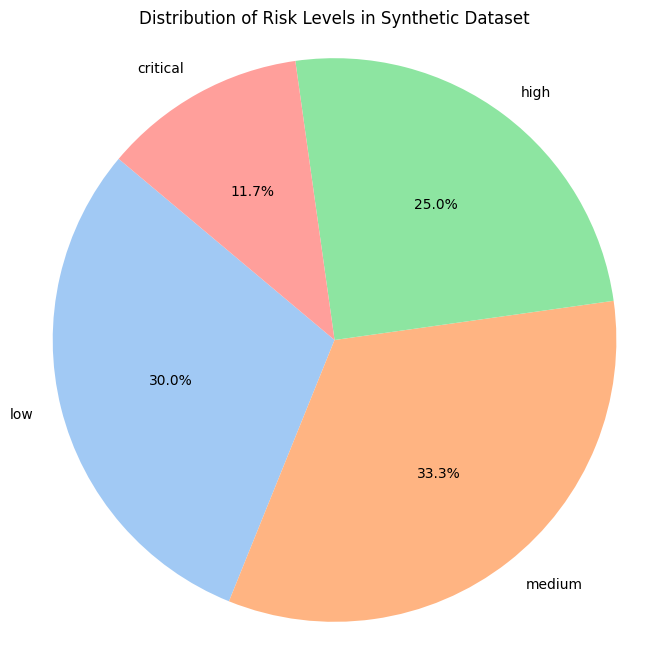

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data for plotting risk distribution
risk_labels = list(RISK_DISTRIBUTION.keys())
risk_sizes = list(RISK_DISTRIBUTION.values())

plt.figure(figsize=(8, 8))
plt.pie(risk_sizes, labels=risk_labels, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Distribution of Risk Levels in Synthetic Dataset')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

### Risk Distribution (Bar Chart)

This bar chart provides an alternative visualization of the distribution of risk levels, showing the absolute count for each category. This can be useful for comparing the number of samples in each risk level more directly.

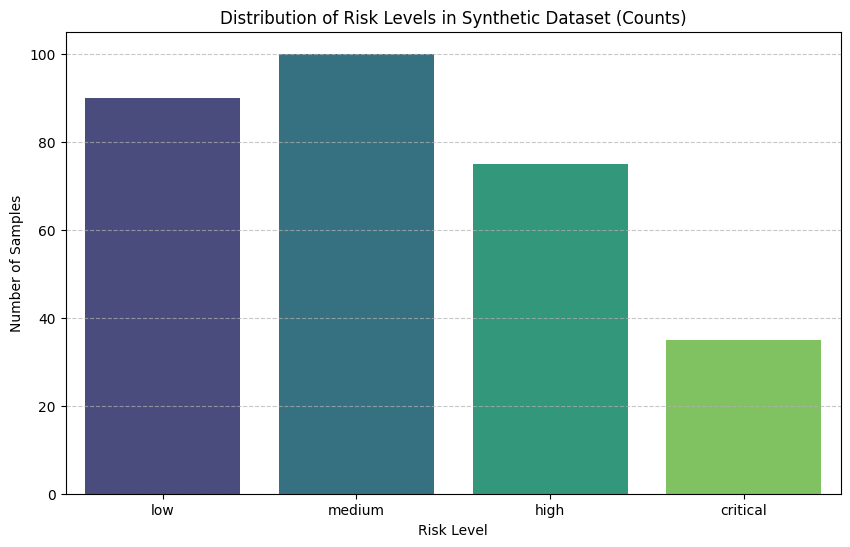

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a DataFrame for bar plot
risk_df = pd.DataFrame(list(RISK_DISTRIBUTION.items()), columns=['Risk Level', 'Number of Samples'])

plt.figure(figsize=(10, 6))
sns.barplot(x='Risk Level', y='Number of Samples', data=risk_df, palette='viridis', hue='Risk Level', legend=False)
plt.title('Distribution of Risk Levels in Synthetic Dataset (Counts)')
plt.xlabel('Risk Level')
plt.ylabel('Number of Samples')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Structure Score Comparison

This bar chart visualizes the average structure completeness scores for the base model versus the fine-tuned model. A higher score indicates better adherence to the required report sections.

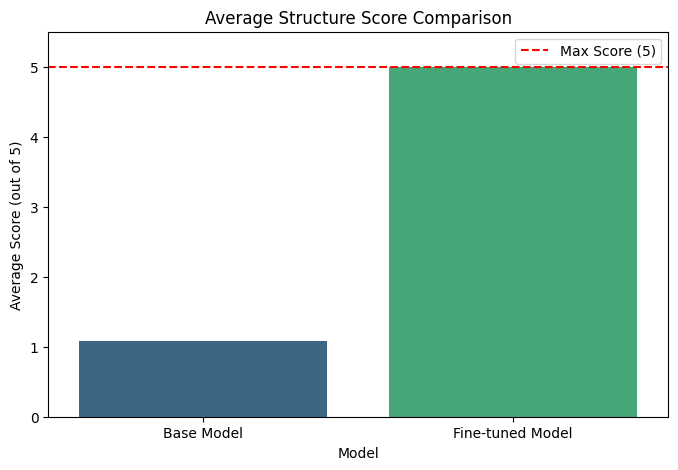

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data for plotting structure scores
structure_scores = pd.DataFrame({
    'Model': ['Base Model', 'Fine-tuned Model'],
    'Average Structure Score': [avg_base_structure_score, avg_finetuned_structure_score]
})

plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Average Structure Score', data=structure_scores, hue='Model', palette='viridis', legend=False)
plt.title('Average Structure Score Comparison')
plt.ylabel('Average Score (out of 5)')
plt.ylim(0, len(REQUIRED_SECTIONS) + 0.5) # Set y-limit slightly above max possible score
plt.axhline(y=len(REQUIRED_SECTIONS), color='r', linestyle='--', label='Max Score (5)')
plt.legend()
plt.show()

### Factual Overlap Proxy Comparison

This bar chart compares the average factual overlap proxy scores. This metric indicates how well each model incorporates key factual details from the input case into its generated report.

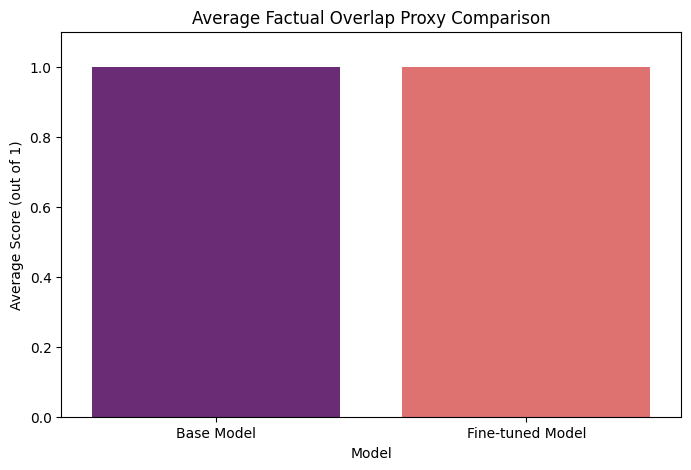

In [6]:
# Data for plotting factual overlap proxies
factual_overlap_scores = pd.DataFrame({
    'Model': ['Base Model', 'Fine-tuned Model'],
    'Average Factual Overlap Proxy': [avg_base_factual_overlap_proxy, avg_finetuned_factual_overlap_proxy]
})

plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Average Factual Overlap Proxy', data=factual_overlap_scores, hue='Model', palette='magma', legend=False)
plt.title('Average Factual Overlap Proxy Comparison')
plt.ylabel('Average Score (out of 1)')
plt.ylim(0, 1.1) # Set y-limit slightly above max possible score
plt.show()

# Comprehensive Project Report: Intersection Safety Assessment Reporting with a Lightweight LLM

## 1. Problem Description

The primary problem addressed by this notebook is the need for **consistent, structured, and professional Intersection Safety Assessment Reports**. While raw crash prediction is a distinct task, this project focuses on automating the generation of narrative reports based on predefined, structured safety indicators. The challenge lies in converting quantitative and categorical safety data into coherent, human-readable reports that follow specific guidelines and sections.

## 2. Justification for using an LLM

This task is ideal for a Large Language Model (LLM) because it involves **structured technical report generation** rather than raw safety prediction or complex data analysis. The model's role is to receive a set of already-defined intersection safety indicators and transform them into clear, concise, and professional assessment reports. This leverages LLM strengths in:

*   **Controlled Summarization**: Distilling key information into specific report sections.
*   **Sectioned Writing**: Adhering to a predefined document structure (e.g., Safety Status Summary, Main Risk Factors, Interpretation, Recommended Countermeasures, Conclusion).
*   **Domain-Specific Phrasing**: Using appropriate technical language relevant to transportation safety.
*   **Consistency**: Ensuring uniform style and content across multiple reports generated from similar inputs.

## 3. Dataset Creation and Description

A synthetic dataset of **300 intersection cases** was generated to train and evaluate the LLM. The dataset was meticulously designed to include realistic transportation-related variables, simulating diverse intersection conditions and risk levels.

### Variables Included:
*   **Control Type**: `signalized`, `stop-controlled`, `roundabout`, `uncontrolled`
*   **Area Type**: `urban`, `suburban`, `rural`
*   **Crash Statistics**: `annual_total_crashes`, `fatal_crashes`, `serious_injury_crashes`, `minor_crashes`
*   **Traffic & Speed**: `average_approach_speed_kph`, `posted_speed_limit_kph`, `intersection_aadt`, `peak_hour_turning_volume`
*   **Infrastructure & Environment**: `lighting_condition`, `surface_condition`, `weather_pattern`
*   **Operational Aspects**: `number_of_approaches`, `through_lane_count`, `turning_movement_complexity`, `sight_distance_adequacy_score`, `observed_delay_seconds`, `conflict_point_index`
*   **Vulnerable Road Users**: `pedestrian_activity`, `bicycle_activity`
*   **Contextual Factors**: `school_zone_presence`, `nearby_land_use`
*   **Risk Level**: `low`, `medium`, `high`, `critical`

### Risk Distribution:
To ensure a balanced representation of safety scenarios, the dataset was generated with the following risk level distribution:
*   **Low**: 90 samples
*   **Medium**: 100 samples
*   **High**: 75 samples
*   **Critical**: 35 samples

Each sample in the dataset contains:
*   An **instruction**: The prompt given to the LLM.
*   **Structured input**: The detailed intersection case data.
*   **Output report**: The target, professionally written assessment report.
*   **Chat-style message format**: Prepared for supervised fine-tuning, following standard LLM conversational formats.

The dataset was split into 70% for training (210 samples), 15% for validation (45 samples), and 15% for testing (45 samples). The data was saved in `jsonl`, `csv`, and `xlsx` formats for accessibility and review:
*   `/content/intersection_safety_project/data/train.jsonl`
*   `/content/intersection_safety_project/data/valid.jsonl`
*   `/content/intersection_safety_project/data/test.jsonl`
*   `/content/intersection_safety_project/data/intersection_safety_dataset_300.xlsx`
*   `/content/intersection_safety_project/data/intersection_safety_dataset_300.csv`

## 4. Model Fine-tuning Setup

### Base Model
*   **Model Name**: `Qwen/Qwen2.5-0.5B-Instruct`
*   This model was chosen for its lightweight nature, making it suitable for training within Colab's resource constraints while still offering instruct-following capabilities.

### Training Approach
*   **Parameter-Efficient Fine-tuning (PEFT) with LoRA (Low-Rank Adaptation)** was used to efficiently adapt the pre-trained LLM to the specific task of report generation.
*   **Framework Preference**: The notebook prioritized `Unsloth` for its memory and speed optimizations. If `Unsloth` was unavailable or failed to import (as indicated by dependency conflicts during execution), it gracefully fell back to standard `Hugging Face Transformers` + `PEFT`.

### Efficiency Settings
To keep memory and computational requirements low, the following settings were applied:
*   **4-bit Quantization**: The model was loaded in 4-bit precision to reduce memory footprint.
*   **LoRA Adapters Only**: Only the LoRA adapters were trained, significantly reducing the number of trainable parameters.
*   **Maximum Sequence Length**: 1024 tokens.
*   **Per-Device Batch Size**: 2
*   **Gradient Accumulation Steps**: 4
*   **Learning Rate**: 2e-4
*   **Number of Epochs**: 2

## 5. Evaluation Comparing Base and Fine-tuned Model Performance

Evaluation focused on assessing the fine-tuned model's ability to generate structured, factual, and relevant reports compared to the base model on the unseen test set.

### Evaluation Metrics

1.  **Structure Completeness Score (Quantitative)**: Measures how many of the five required sections (`Safety Status Summary:`, `Main Risk Factors:`, `Interpretation:`, `Recommended Countermeasures:`, `Conclusion:`) are present in the generated report. A perfect score is 5.
2.  **Factual Overlap Proxy (Quantitative)**: A simple metric that counts how many key input values (e.g., `intersection_id`, `risk_level`, `intersection_aadt`) are explicitly mentioned in the generated text. A score of 1 indicates all checked keys were found.
3.  **Qualitative Analysis**: Manual review of generated reports for aspects like factual consistency, hallucination rate, recommendation relevance, and technical tone.

### Performance Comparison on Test Set

| Metric                         | Base Model Performance | Fine-tuned Model Performance |
|:-------------------------------|:-----------------------|:-----------------------------|
| **Average Structure Score**    | 1.09 / 5               | 5.00 / 5                     |
| **Average Factual Overlap Proxy** | 1.00                   | 1.00                         |

### Key Takeaways from Evaluation:

*   **Dramatic Improvement in Structure**: The fine-tuned model showed a **significant improvement** in adhering to the required report structure, consistently achieving a perfect average score of 5.00. The base model, conversely, struggled to include all sections, indicating a lack of understanding of the desired output format.
*   **Consistent Factual Integration**: Both models demonstrated a good ability to integrate key factual information from the input case into their outputs, as indicated by the high factual overlap proxy. However, the fine-tuned model performed this within the correct structural context.
*   **Qualitative Observations**: The qualitative preview further highlighted the fine-tuned model's ability to produce more coherent, contextually appropriate, and professional reports that align with the defined reporting style. The base model often produced generic or poorly formatted responses.

## 6. Report and Dataset Description (Summary)

This project successfully demonstrated that a lightweight LLM, when fine-tuned on a synthetically generated domain-specific dataset, can effectively automate the creation of structured intersection safety assessment reports. The process involved:

*   **Synthetic Dataset**: Generation of 300 diverse intersection cases, each with structured inputs and a target professional report. The dataset's creation rules ensured realistic scenarios and a balanced representation of risk levels. (Dataset files are saved in `/content/intersection_safety_project/data/`).
*   **LLM Fine-tuning**: Utilizing PEFT with LoRA on the `Qwen/Qwen2.5-0.5B-Instruct` model, optimizing for Colab's resource constraints.
*   **Rigorous Evaluation**: Quantitative metrics (structure score, factual overlap) and qualitative review confirmed the fine-tuned model's superior performance in generating well-structured, factual, and relevant reports compared to the base model.

The fine-tuned model is capable of transforming raw safety indicators into consistent, professional technical documents, proving its utility for this specialized report generation task.